<a href="https://colab.research.google.com/github/Nakib-Nasrullah/Research-Skill/blob/main/Data_Science_Class_KNN%2C_Decision_Trees_%26_Random_Forests.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **Data Science Class: KNN, Decision Trees & Random Forests**
## KNN, Decision Trees & Random Forests

---

## **Project Goal:**
Predict whether a patient has diabetes based on medical measurements

## **Dataset:**
- **Name:** Pima Indians Diabetes Dataset
- **Samples:** 768 patients
- **Features:** 8 medical measurements
- **Target:** Outcome (0 = No Diabetes, 1 = Has Diabetes)

---

## **Table of Contents**

1. [Theory: Classification Algorithms](#theory)
2. [Import Libraries](#import)
3. [Load Dataset](#load)
4. [Data Exploration](#explore)
5. [Data Preparation](#prepare)
6. [Model 1: KNN](#knn)
7. [Model 2: Decision Tree](#dt)
8. [Model 3: Random Forest](#rf)
9. [Model Comparison](#compare)
10. [Homework Assignment](#homework)

---

<a id='theory'></a>
## **1. Theory: Classification Algorithms**

### **What is Classification?**
Classification divides data into categories (classes).

**Today's Example:** Does this patient have diabetes? YES or NO

---

### **Algorithm 1: K-Nearest Neighbors (KNN)**

**Concept:** "You are like your neighbors"

**How it works:**
1. Find the K closest patients (neighbors)
2. Check their diabetes status
3. Majority vote wins!

**Example (K=5):**
- 3 neighbors have diabetes → Prediction: **HAS DIABETES**
- 2 neighbors are healthy →

**Distance Metric:** Euclidean Distance = √(Σ(x₂-x₁)²)
**Manhatan Distance = Σ|Xi - Yi |

---

### **Algorithm 2: Decision Tree**

**Concept:** "Ask questions to make decisions"

**Example Decision Tree:**
```
Is Glucose > 120?
├─ YES → Is BMI > 30?
│        ├─ YES → DIABETES
│        └─ NO → Is Age > 50?
│                ├─ YES → DIABETES
│                └─ NO → HEALTHY
└─ NO → HEALTHY
```

**Splitting Criteria:** Gini Index (measures impurity)
- Gini = 0 → Pure (all same class)
- Gini = 0.5 → Impure (mixed classes)

---

### **Algorithm 3: Random Forest**

**Concept:** "Wisdom of the crowd"

**How it works:**
1. Create 100 different decision trees
2. Each tree votes
3. Majority wins!

**Example:**
- 70 trees say: DIABETES
- 30 trees say: HEALTHY
- **Final Prediction: DIABETES**

**Benefits:**
- More accurate than single tree
- Less overfitting
- Shows feature importance

---

<a id='import'></a>
## **2. Import Libraries**

In [1]:
# Data handling and visualization
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Machine Learning
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

# Settings
import warnings
warnings.filterwarnings('ignore')
sns.set_style('whitegrid')

print("✅ All libraries imported successfully!")

✅ All libraries imported successfully!


<a id='load'></a>
## **3. Load Dataset**


In [2]:
from google.colab import drive
drive.mount('/content/drive')

df = pd.read_csv('/content/drive/MyDrive/Datasets/diabetes.csv')
print("✅ Dataset loaded successfully!")
print(f"\n📊 Dataset Shape: {df.shape}")

Mounted at /content/drive
✅ Dataset loaded successfully!

📊 Dataset Shape: (768, 9)


<a id='explore'></a>
## **4. Data Exploration**

Let's understand our data!

In [3]:
# View first 5 rows
print("📋 First 5 Patients:")
df.head()

📋 First 5 Patients:


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


In [4]:
# Dataset information
print("📊 Dataset Information:")
df.info()


📊 Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 9 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Pregnancies               768 non-null    int64  
 1   Glucose                   768 non-null    int64  
 2   BloodPressure             768 non-null    int64  
 3   SkinThickness             768 non-null    int64  
 4   Insulin                   768 non-null    int64  
 5   BMI                       768 non-null    float64
 6   DiabetesPedigreeFunction  768 non-null    float64
 7   Age                       768 non-null    int64  
 8   Outcome                   768 non-null    int64  
dtypes: float64(2), int64(7)
memory usage: 54.1 KB


In [5]:
# Statistical summary
print("📈 Statistical Summary:")
df.describe().T

📈 Statistical Summary:


,count,mean,std,min,25%,50%,75%,max
Pregnancies,768.0,3.845052,3.369578,0.000,1.00000,3.0000,6.00000,17.00
Glucose,768.0,120.894531,31.972618,0.000,99.00000,117.0000,140.25000,199.00
BloodPressure,768.0,69.105469,19.355807,0.000,62.00000,72.0000,80.00000,122.00
SkinThickness,768.0,20.536458,15.952218,0.000,0.00000,23.0000,32.00000,99.00
Insulin,768.0,79.799479,115.244002,0.000,0.00000,30.5000,127.25000,846.00
BMI,768.0,31.992578,7.884160,0.000,27.30000,32.0000,36.60000,67.10
DiabetesPedigreeFunction,768.0,0.471876,0.331329,0.078,0.24375,0.3725,0.62625,2.42
Age,768.0,33.240885,11.760232,21.000,24.00000,29.0000,41.00000,81.00
Outcome,768.0,0.348958,0.476951,0.000,0.00000,0.0000,1.00000,1.00


Outcome
0    500
1    268
Name: count, dtype: int64


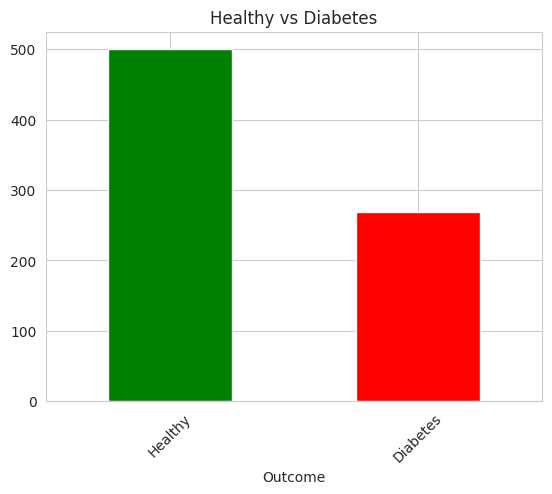

In [6]:
# Show distribution
print(df['Outcome'].value_counts())

# Plot
df['Outcome'].value_counts().plot(kind='bar', color=['green', 'red'])
plt.title('Healthy vs Diabetes')
plt.xticks([0, 1], ['Healthy', 'Diabetes'], rotation=45)
plt.show()

<a id='prepare'></a>
## **5. Data Preparation**

Prepare data for machine learning models

In [7]:
# Separate Features (X) and Target (y)
X = df.drop('Outcome', axis=1)  # All columns except Outcome
y = df['Outcome']  # Only the Outcome column

print("✅ Features (X):")
print(f"   Shape: {X.shape}")
print(f"   Columns: {X.columns.tolist()}")

print("\n✅ Target (y):")
print(f"   Shape: {y.shape}")
print(f"   Values: 0 (Healthy) and 1 (Diabetes)")

✅ Features (X):
   Shape: (768, 8)
   Columns: ['Pregnancies', 'Glucose', 'BloodPressure', 'SkinThickness', 'Insulin', 'BMI', 'DiabetesPedigreeFunction', 'Age']

✅ Target (y):
   Shape: (768,)
   Values: 0 (Healthy) and 1 (Diabetes)


In [8]:
# Split into Training (80%) and Testing (20%)
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=20
)

print("✅ Data Split:")
print(f"   Training: {X_train.shape[0]} patients ({X_train.shape[0]/len(df)*100:.0f}%)")
print(f"   Testing:  {X_test.shape[0]} patients ({X_test.shape[0]/len(df)*100:.0f}%)")

✅ Data Split:
   Training: 614 patients (80%)
   Testing:  154 patients (20%)


In [9]:
# Feature Scaling (IMPORTANT for KNN!)
print("⚙️ Scaling features...\n")

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("✅ Feature scaling completed!")


⚙️ Scaling features...

✅ Feature scaling completed!


<a id='knn'></a>
## **6. Model 1: K-Nearest Neighbors (KNN)**

Best K: 4


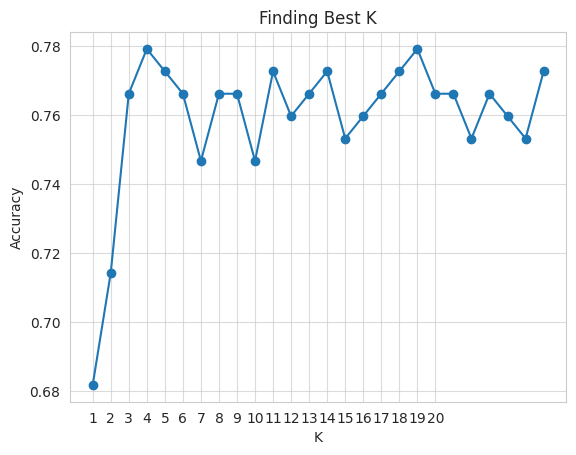

In [12]:
# Find best K
accuracies = []
for k in range(1, 27):
    knn = KNeighborsClassifier(n_neighbors=k)
    knn.fit(X_train_scaled, y_train)
    accuracies.append(accuracy_score(y_test, knn.predict(X_test_scaled)))

best_k = accuracies.index(max(accuracies)) + 1
print(f"Best K: {best_k}")

# Plot
plt.plot(range(1, 27), accuracies, marker='o')
plt.xlabel('K')
plt.ylabel('Accuracy')
plt.xticks(range(1, 21))
plt.title('Finding Best K')
plt.grid(alpha=0.7)
plt.show()

In [13]:
# Train final KNN model
print(f"\n🤖 Training KNN with K = {best_k}...\n")

knn_model = KNeighborsClassifier(n_neighbors=best_k)
knn_model.fit(X_train_scaled, y_train)
y_pred_knn = knn_model.predict(X_test_scaled)
knn_accuracy = accuracy_score(y_test, y_pred_knn)

print("✅ KNN Model trained!")
print(f"\n📊 KNN Accuracy: {knn_accuracy:.4f} ({knn_accuracy*100:.2f}%)")


🤖 Training KNN with K = 4...

✅ KNN Model trained!

📊 KNN Accuracy: 0.7792 (77.92%)



📋 KNN Classification Report:
              precision    recall  f1-score   support

     Healthy       0.79      0.91      0.84       101
    Diabetes       0.76      0.53      0.62        53

    accuracy                           0.78       154
   macro avg       0.77      0.72      0.73       154
weighted avg       0.78      0.78      0.77       154



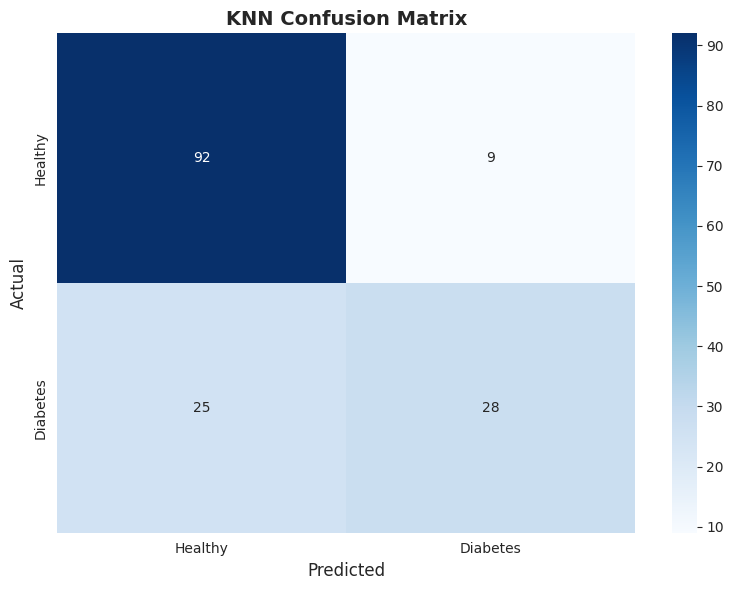

In [14]:
# Evaluation
print("\n📋 KNN Classification Report:")
print("=" * 60)
print(classification_report(y_test, y_pred_knn, target_names=['Healthy', 'Diabetes']))

# Confusion Matrix
cm_knn = confusion_matrix(y_test, y_pred_knn)

plt.figure(figsize=(8, 6))
sns.heatmap(cm_knn, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Healthy', 'Diabetes'],
            yticklabels=['Healthy', 'Diabetes'])
plt.title('KNN Confusion Matrix', fontsize=14, fontweight='bold')
plt.ylabel('Actual', fontsize=12)
plt.xlabel('Predicted', fontsize=12)
plt.tight_layout()
plt.show()

print("\n" + "="*60)

<a id='dt'></a>
## **7. Model 2: Decision Tree**

In [15]:
# Train Decision Tree
print("🌳 Training Decision Tree...\n")

dt_model = DecisionTreeClassifier(
    criterion='gini',
    max_depth=5,          # Limit depth to avoid overfitting
    min_samples_split=20,
    min_samples_leaf=10,
    random_state=42
)

dt_model.fit(X_train, y_train)  # No scaling needed
y_pred_dt = dt_model.predict(X_test)
dt_accuracy = accuracy_score(y_test, y_pred_dt)

print("✅ Decision Tree trained!")
print(f"\n📊 Decision Tree Accuracy: {dt_accuracy:.4f} ({dt_accuracy*100:.2f}%)")

🌳 Training Decision Tree...

✅ Decision Tree trained!

📊 Decision Tree Accuracy: 0.7208 (72.08%)



📋 Decision Tree Classification Report:
              precision    recall  f1-score   support

     Healthy       0.76      0.83      0.80       101
    Diabetes       0.61      0.51      0.56        53

    accuracy                           0.72       154
   macro avg       0.69      0.67      0.68       154
weighted avg       0.71      0.72      0.71       154



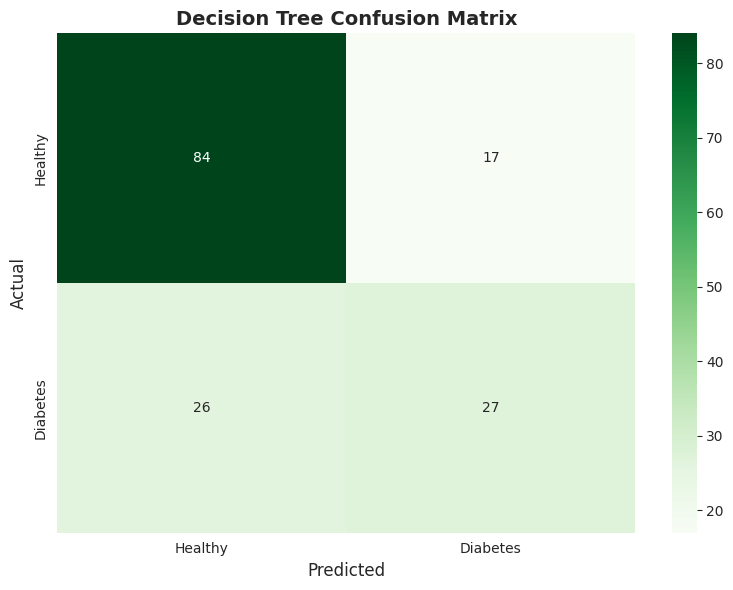

In [16]:
# Evaluation
print("\n📋 Decision Tree Classification Report:")
print("=" * 60)
print(classification_report(y_test, y_pred_dt, target_names=['Healthy', 'Diabetes']))

# Confusion Matrix
cm_dt = confusion_matrix(y_test, y_pred_dt)

plt.figure(figsize=(8, 6))
sns.heatmap(cm_dt, annot=True, fmt='d', cmap='Greens',
            xticklabels=['Healthy', 'Diabetes'],
            yticklabels=['Healthy', 'Diabetes'])
plt.title('Decision Tree Confusion Matrix', fontsize=14, fontweight='bold')
plt.ylabel('Actual', fontsize=12)
plt.xlabel('Predicted', fontsize=12)
plt.tight_layout()
plt.show()

print("\n" + "="*60)


⭐ Feature Importance (Decision Tree):
                 Feature  Importance
                 Glucose    0.495251
                     BMI    0.250011
                     Age    0.110900
DiabetesPedigreeFunction    0.076979
             Pregnancies    0.039843
                 Insulin    0.019007
           BloodPressure    0.008009
           SkinThickness    0.000000


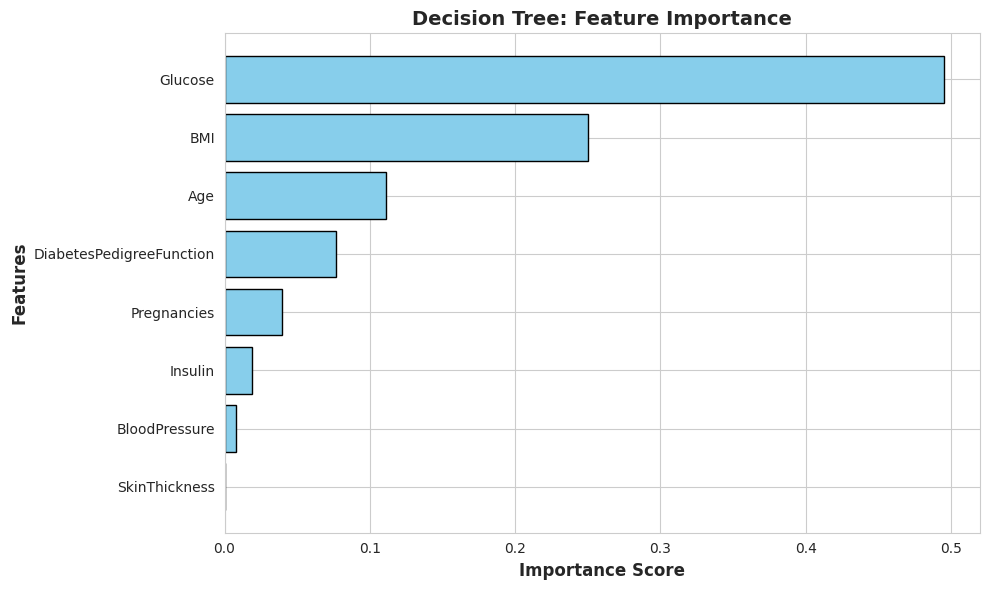


💡 These features are most important for prediction!



In [17]:
# Feature Importance
print("\n⭐ Feature Importance (Decision Tree):")
print("=" * 60)

feature_importance = pd.DataFrame({
    'Feature': X.columns,
    'Importance': dt_model.feature_importances_
}).sort_values('Importance', ascending=False)

print(feature_importance.to_string(index=False))

# Plot
plt.figure(figsize=(10, 6))
plt.barh(feature_importance['Feature'], feature_importance['Importance'],
         color='skyblue', edgecolor='black')
plt.xlabel('Importance Score', fontsize=12, fontweight='bold')
plt.ylabel('Features', fontsize=12, fontweight='bold')
plt.title('Decision Tree: Feature Importance', fontsize=14, fontweight='bold')
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

print("\n💡 These features are most important for prediction!")
print("\n" + "="*60)

<a id='rf'></a>
## **8. Model 3: Random Forest**

In [18]:
# Train Random Forest
print("🌲🌳🌲 Training Random Forest...\n")

rf_model = RandomForestClassifier(
    n_estimators=100,     # 100 trees
    max_depth=5,
    min_samples_split=20,
    min_samples_leaf=10,
    random_state=42,
    n_jobs=-1             # Use all CPU cores
)

rf_model.fit(X_train, y_train)
y_pred_rf = rf_model.predict(X_test)
rf_accuracy = accuracy_score(y_test, y_pred_rf)

print("✅ Random Forest trained!")
print(f"   → {rf_model.n_estimators} trees created")
print(f"   → Each tree votes")
print(f"\n📊 Random Forest Accuracy: {rf_accuracy:.4f} ({rf_accuracy*100:.2f}%)")

🌲🌳🌲 Training Random Forest...

✅ Random Forest trained!
   → 100 trees created
   → Each tree votes

📊 Random Forest Accuracy: 0.7532 (75.32%)



📋 Random Forest Classification Report:
              precision    recall  f1-score   support

     Healthy       0.76      0.91      0.83       101
    Diabetes       0.73      0.45      0.56        53

    accuracy                           0.75       154
   macro avg       0.74      0.68      0.69       154
weighted avg       0.75      0.75      0.74       154



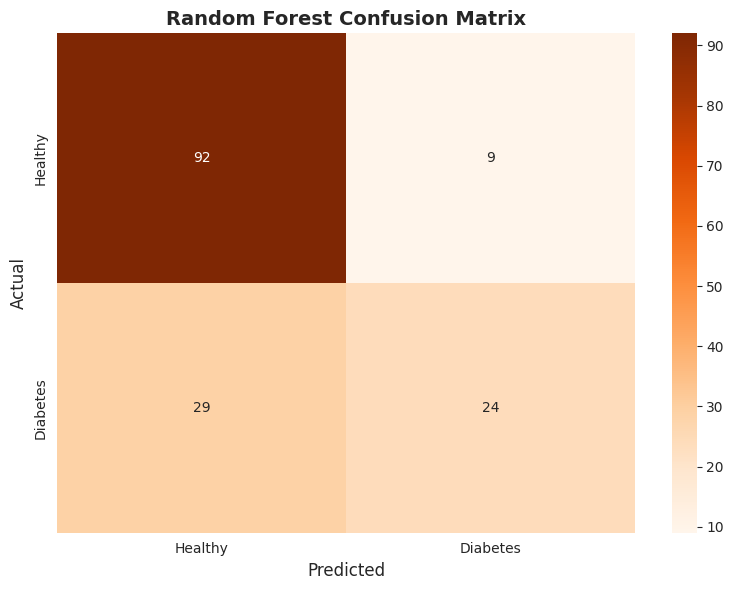

In [19]:
# Evaluation
print("\n📋 Random Forest Classification Report:")
print("=" * 60)
print(classification_report(y_test, y_pred_rf, target_names=['Healthy', 'Diabetes']))

# Confusion Matrix
cm_rf = confusion_matrix(y_test, y_pred_rf)

plt.figure(figsize=(8, 6))
sns.heatmap(cm_rf, annot=True, fmt='d', cmap='Oranges',
            xticklabels=['Healthy', 'Diabetes'],
            yticklabels=['Healthy', 'Diabetes'])
plt.title('Random Forest Confusion Matrix', fontsize=14, fontweight='bold')
plt.ylabel('Actual', fontsize=12)
plt.xlabel('Predicted', fontsize=12)
plt.tight_layout()
plt.show()

print("\n" + "="*60)


⭐ Feature Importance (Random Forest):
                 Feature  Importance
                 Glucose    0.386715
                     BMI    0.174215
                     Age    0.146147
             Pregnancies    0.085922
DiabetesPedigreeFunction    0.073032
                 Insulin    0.054665
           SkinThickness    0.041170
           BloodPressure    0.038135


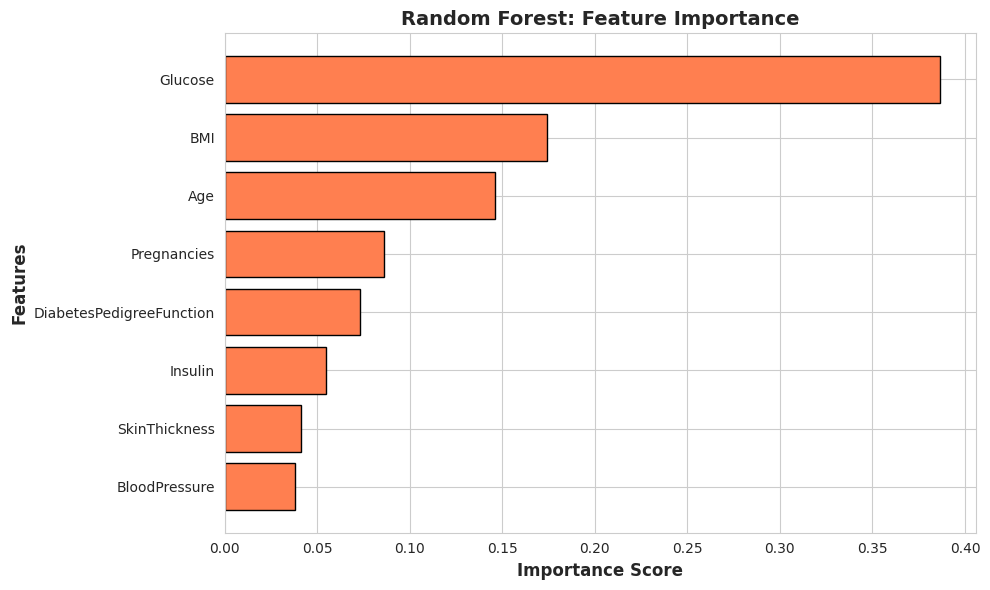


💡 Random Forest importance is more reliable!
   (Average of 100 trees)



In [20]:
# Feature Importance
print("\n⭐ Feature Importance (Random Forest):")
print("=" * 60)

rf_feature_importance = pd.DataFrame({
    'Feature': X.columns,
    'Importance': rf_model.feature_importances_
}).sort_values('Importance', ascending=False)

print(rf_feature_importance.to_string(index=False))

# Plot
plt.figure(figsize=(10, 6))
plt.barh(rf_feature_importance['Feature'], rf_feature_importance['Importance'],
         color='coral', edgecolor='black')
plt.xlabel('Importance Score', fontsize=12, fontweight='bold')
plt.ylabel('Features', fontsize=12, fontweight='bold')
plt.title('Random Forest: Feature Importance', fontsize=14, fontweight='bold')
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

print("\n💡 Random Forest importance is more reliable!")
print("   (Average of 100 trees)")
print("\n" + "="*60)

<a id='compare'></a>
## **9. Model Comparison & Final Results**

In [21]:
# Compare all models
print("\n🏆 FINAL MODEL COMPARISON")
print("=" * 60)

comparison = pd.DataFrame({
    'Model': ['KNN', 'Decision Tree', 'Random Forest'],
    'Accuracy': [knn_accuracy, dt_accuracy, rf_accuracy],
    'Accuracy %': [f"{knn_accuracy*100:.2f}%", f"{dt_accuracy*100:.2f}%", f"{rf_accuracy*100:.2f}%"]
})

comparison = comparison.sort_values('Accuracy', ascending=False)
print("\n" + comparison.to_string(index=False))

best_model = comparison.iloc[0]['Model']
best_acc = comparison.iloc[0]['Accuracy']

print(f"\n🥇 WINNER: {best_model}")
print(f"   Accuracy: {best_acc:.4f} ({best_acc*100:.2f}%)")
print("\n" + "="*60)


🏆 FINAL MODEL COMPARISON

        Model  Accuracy Accuracy %
          KNN  0.779221     77.92%
Random Forest  0.753247     75.32%
Decision Tree  0.720779     72.08%

🥇 WINNER: KNN
   Accuracy: 0.7792 (77.92%)



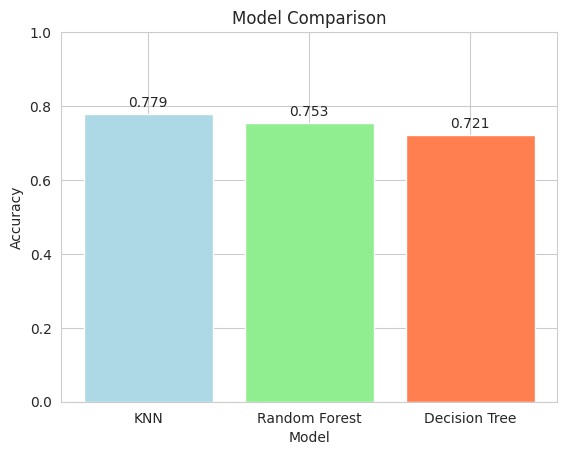

In [ ]:
# Visual Comparison
plt.bar(comparison['Model'], comparison['Accuracy'], color=['lightblue', 'lightgreen', 'coral'])
plt.xlabel('Model')
plt.ylabel('Accuracy')
plt.title('Model Comparison')
plt.ylim([0, 1])

# Add values on bars
for i, acc in enumerate(comparison['Accuracy']):
    plt.text(i, acc + 0.02, f'{acc:.3f}', ha='center')

plt.show()

## **📝 Summary**

### **What We Learned:**
1. ✅ **KNN** - Simple, distance-based, good for small datasets
2. ✅ **Decision Tree** - Fast, interpretable, shows feature importance
3. ✅ **Random Forest** - Most accurate, combines many trees

### **Key Findings:**
- **Most Important Features:** Glucose, BMI, Age, Pregnancies
- **Best Model:** Depends on your results (likely Random Forest!)
- **Accuracy:** ~75-80% is typical for this dataset

### **Real-World Application:**
This model could help doctors:
- Screen patients for diabetes risk
- Identify high-risk individuals early
- Prioritize patients for testing

---

<a id='homework'></a>
## **10. 📚 Assignment: Heart Disease Prediction**

### **Assignment:**
Apply the same three algorithms to predict heart disease!

---

### **Dataset Information:**
**Name:** Heart Disease Dataset  
**Link:** https://www.kaggle.com/datasets/johnsmith88/heart-disease-dataset  
**Size:** 303 patients  
**Features:** 13 medical measurements  
**Target:** 0 = No heart disease, 1 = Has heart disease  

### **Features Include:**
- Age, Sex, Chest Pain Type
- Blood Pressure, Cholesterol
- Heart Rate, Exercise indicators
- And more medical measurements

---

### **Your Tasks:**
1. Download the heart disease dataset from Kaggle
2. Upload to Google Colab
3. Load and explore the data
4. Build three models: **KNN, Decision Tree, Random Forest**
5. Compare accuracies and find the best model
6. Identify the most important features


---

### **Expected Results:**
- KNN Accuracy: ~80-82%
- Decision Tree: ~78-80%
- Random Forest: ~82-85%

---

### **Starter Code:**
```python
# Load dataset
df = pd.read_csv('heart.csv')

# Separate features and target
X = df.drop('target', axis=1)  # or 'num' depending on dataset version
y = df['target']

# Follow the same steps as diabetes project!
# 1. Split data
# 2. Scale features
# 3. Build models
# 4. Compare results
```

### **Submission:**
- ✅ Google Colab Notebook (.ipynb file)
- ✅ Screenshots of key results (confusion matrices, comparison chart)


## **🎓 End of Notebook**

**Great job completing this project!** 🎉

### **What You Learned:**
✅ K-Nearest Neighbors (KNN)  
✅ Decision Trees  
✅ Random Forests  
✅ Model Evaluation  
✅ Feature Importance  
✅ Real-world medical prediction  

---

### **Contact:**
**Instructor:** Md. Samiul Islam  
**Lab:** Skill Morph Research Lab  

**Good luck with your Data Science journey! 🚀**